# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Perfume Type Classification Dataset](https://www.kaggle.com/datasets/abacilla/perfume-type-classification/data)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
import sklearn
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import ExtraTreesRegressor
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('perfume_type_classification_dataset.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,fragrance_family,brand_tier,gender_target,contains_alcohol,limited_edition,perfume_category
0,5.96,5.80,5,103.71,17.04,Floral,Designer,Men,0.0,0,Eau de Parfum
1,8.85,7.70,4,122.93,15.28,Oriental,Luxury,Men,1.0,0,Eau de Toilette
2,0.54,2.67,3,105.21,12.69,Fresh,Designer,Men,0.0,0,Eau de Toilette
3,9.83,8.06,7,165.64,20.95,Floral,Luxury,Women,1.0,0,Eau de Parfum
4,11.03,9.72,5,279.00,25.00,Oriental,Luxury,Women,1.0,0,Perfume Extract


## last Five row

In [4]:
df.tail()

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,fragrance_family,brand_tier,gender_target,contains_alcohol,limited_edition,perfume_category
69995,8.29,7.82,6,67.13,7.61,Citrus,Luxury,Men,1.0,0,Eau de Toilette
69996,5.92,3.82,6,71.81,11.16,Oriental,Niche,Women,1.0,0,Eau de Toilette
69997,7.55,5.13,5,23.56,18.84,Citrus,Drugstore,Women,1.0,0,Eau de Parfum
69998,3.09,7.37,5,71.07,21.56,Fresh,Drugstore,Men,1.0,0,Eau de Parfum
69999,0.50,5.81,9,22.27,11.32,Woody,Luxury,Women,1.0,0,Eau de Toilette


## Shape of our dataset

In [5]:
df.shape

(70000, 11)

## List out all columns

In [6]:
df.columns

Index(['longevity_hours', 'sillage_score', 'top_note_count', 'price_usd',
       'concentration_percent', 'fragrance_family', 'brand_tier',
       'gender_target', 'contains_alcohol', 'limited_edition',
       'perfume_category'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

longevity_hours          float64
sillage_score            float64
top_note_count             int64
price_usd                float64
concentration_percent    float64
fragrance_family          object
brand_tier                object
gender_target             object
contains_alcohol         float64
limited_edition            int64
perfume_category          object
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   longevity_hours        70000 non-null  float64
 1   sillage_score          70000 non-null  float64
 2   top_note_count         70000 non-null  int64  
 3   price_usd              69272 non-null  float64
 4   concentration_percent  70000 non-null  float64
 5   fragrance_family       70000 non-null  object 
 6   brand_tier             66497 non-null  object 
 7   gender_target          70000 non-null  object 
 8   contains_alcohol       68251 non-null  float64
 9   limited_edition        70000 non-null  int64  
 10  perfume_category       70000 non-null  object 
dtypes: float64(5), int64(2), object(4)
memory usage: 5.9+ MB


## Check Null Value

In [9]:
df.isnull().sum()

longevity_hours             0
sillage_score               0
top_note_count              0
price_usd                 728
concentration_percent       0
fragrance_family            0
brand_tier               3503
gender_target               0
contains_alcohol         1749
limited_edition             0
perfume_category            0
dtype: int64

## Handle Missing Value

In [10]:
from sklearn.impute import SimpleImputer

imp_mean = SimpleImputer(strategy='mean')
df[['price_usd']] = imp_mean.fit_transform(df[['price_usd']])
imp_mode = SimpleImputer(strategy='most_frequent')
df[['contains_alcohol']] = imp_mode.fit_transform(df[['contains_alcohol']])
df[['brand_tier']] = imp_mode.fit_transform(df[['brand_tier']])
df.isnull().sum()

longevity_hours          0
sillage_score            0
top_note_count           0
price_usd                0
concentration_percent    0
fragrance_family         0
brand_tier               0
gender_target            0
contains_alcohol         0
limited_edition          0
perfume_category         0
dtype: int64

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(15000)

## Drop Duplicate Values

In [12]:
df.drop_duplicates(inplace=True)
df.duplicated().sum()

np.int64(0)

## Summary

In [13]:
df.describe()

,longevity_hours,sillage_score,top_note_count,price_usd,concentration_percent,contains_alcohol,limited_edition
count,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000,55000.000000
mean,5.704677,5.582461,5.361036,98.683834,13.479392,0.856491,0.122436
std,3.180878,2.448936,2.408793,69.139533,7.495383,0.350594,0.327792
min,0.500000,1.000000,1.000000,10.000000,1.500000,0.000000,0.000000
25%,3.360000,3.780000,4.000000,43.290000,7.840000,1.000000,0.000000
50%,5.540000,5.590000,5.000000,90.685000,12.930000,1.000000,0.000000
75%,7.820000,7.400000,7.000000,141.052500,18.410000,1.000000,0.000000
max,16.000000,10.000000,10.000000,428.130000,35.000000,1.000000,1.000000


# EDA

In [14]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

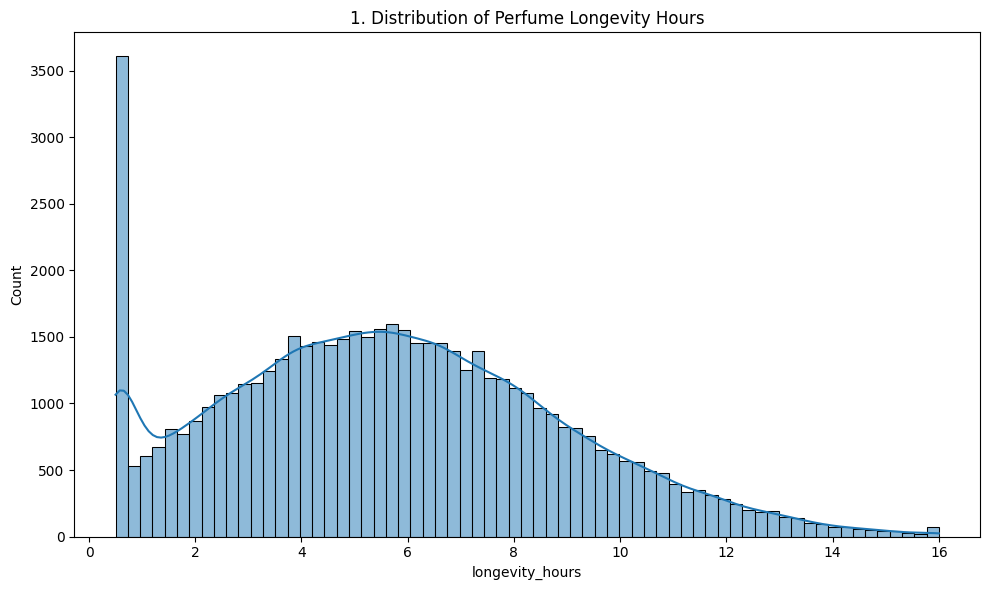

In [15]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='longevity_hours', kde=True)
plt.title(f'{plot_no}. Distribution of Perfume Longevity Hours')
show_fig()
plot_no += 1

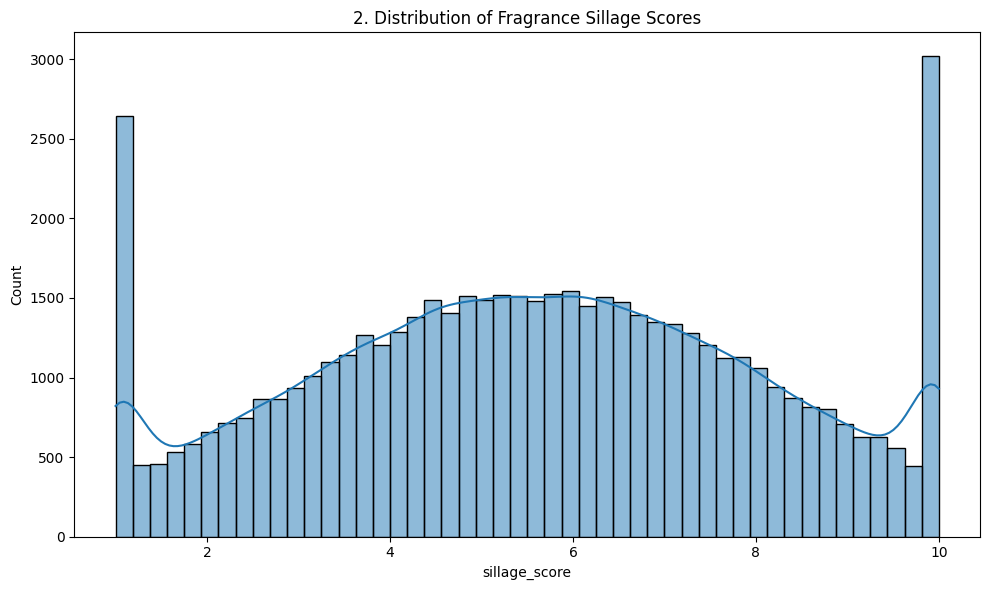

In [16]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='sillage_score', kde=True)
plt.title(f'{plot_no}. Distribution of Fragrance Sillage Scores')
show_fig()
plot_no += 1

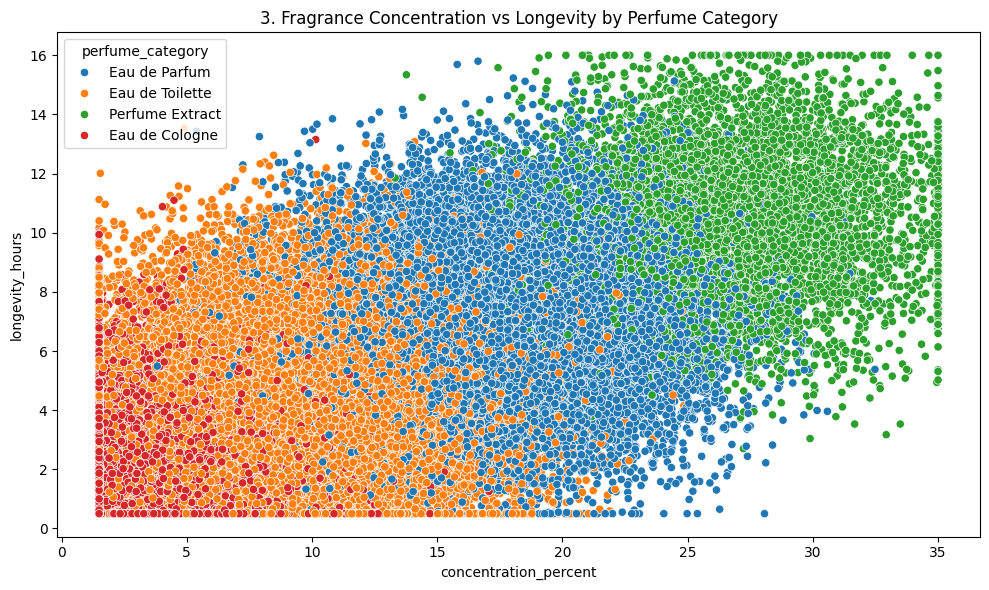

In [17]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='concentration_percent', y='longevity_hours', hue='perfume_category')
plt.title(f'{plot_no}. Fragrance Concentration vs Longevity by Perfume Category')
show_fig()
plot_no += 1

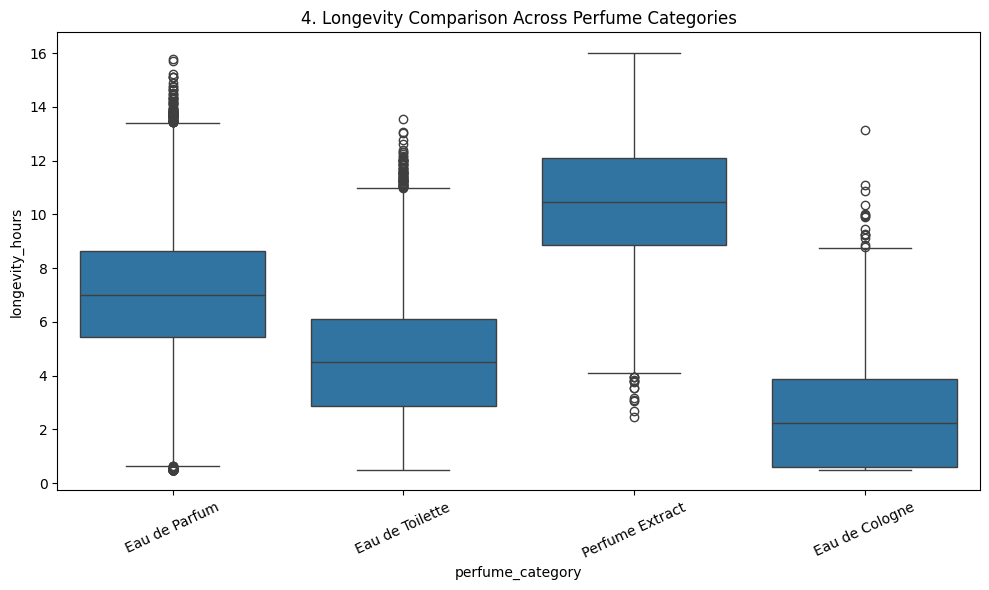

In [18]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='perfume_category', y='longevity_hours')
plt.title(f'{plot_no}. Longevity Comparison Across Perfume Categories')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

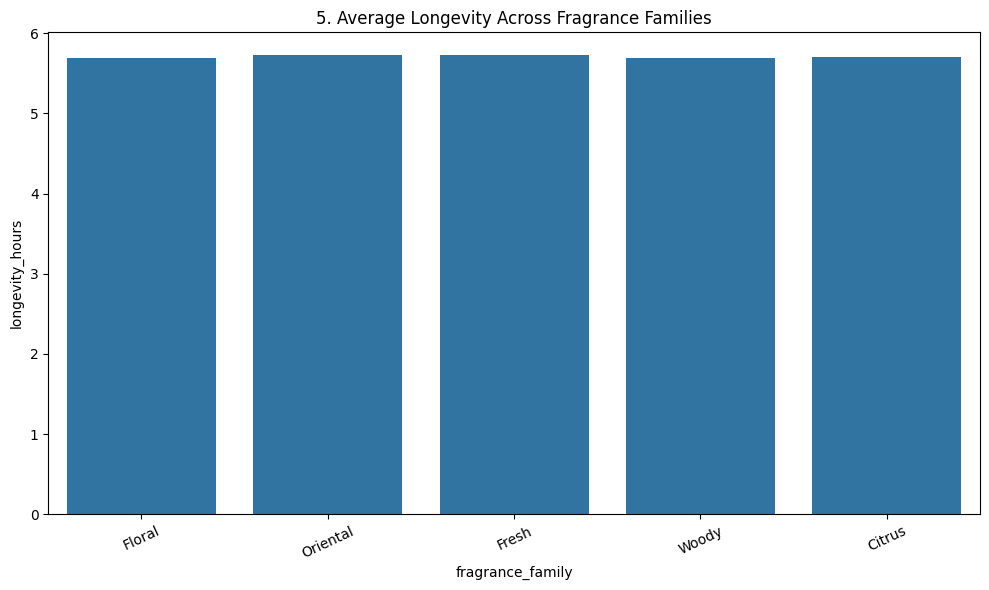

In [19]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='fragrance_family', y='longevity_hours', errorbar=None)
plt.title(f'{plot_no}. Average Longevity Across Fragrance Families')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

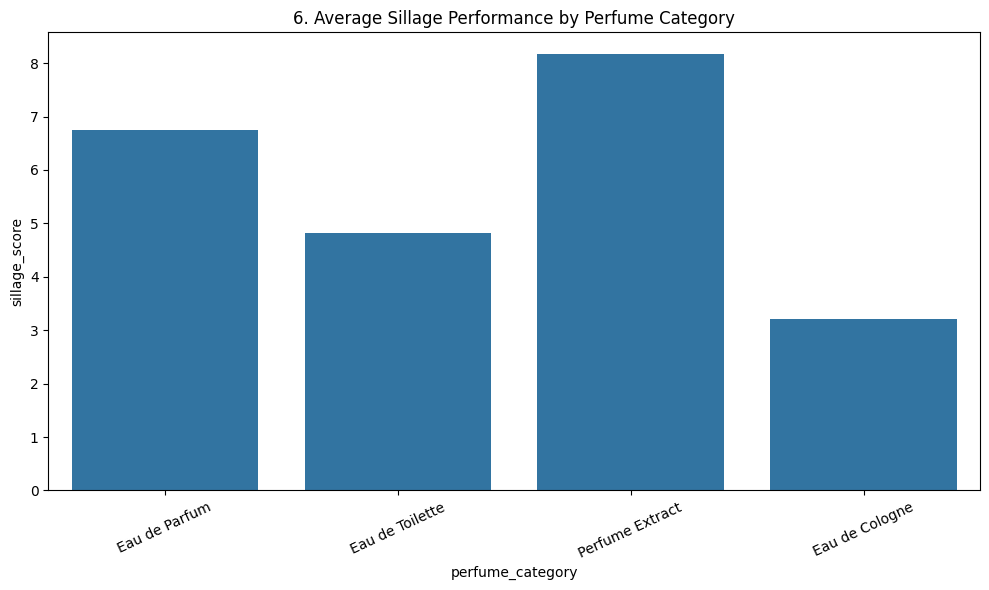

In [20]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='perfume_category', y='sillage_score', errorbar=None)
plt.title(f'{plot_no}. Average Sillage Performance by Perfume Category')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

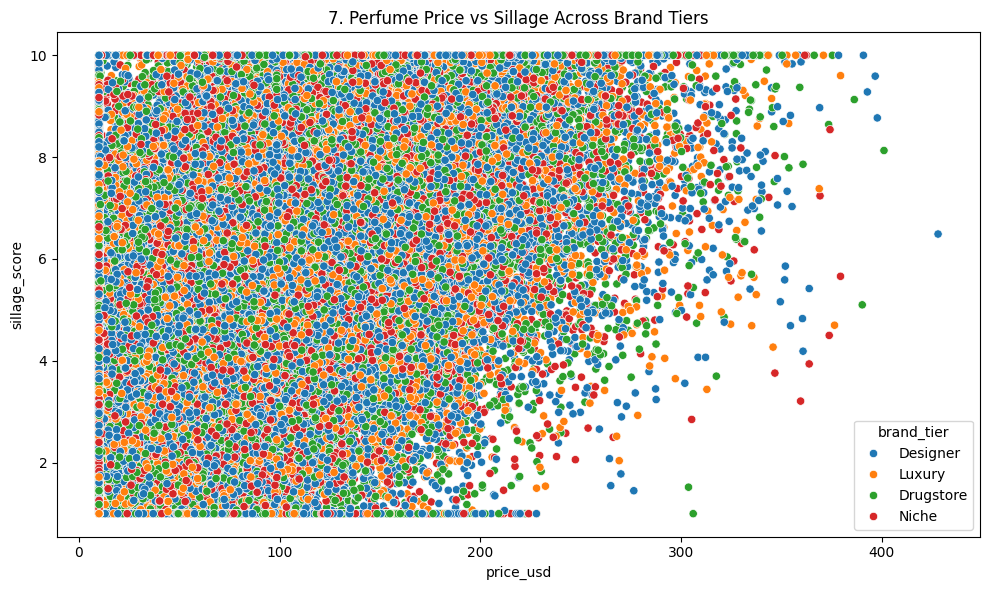

In [21]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='price_usd', y='sillage_score', hue='brand_tier')
plt.title(f'{plot_no}. Perfume Price vs Sillage Across Brand Tiers')
show_fig()
plot_no += 1

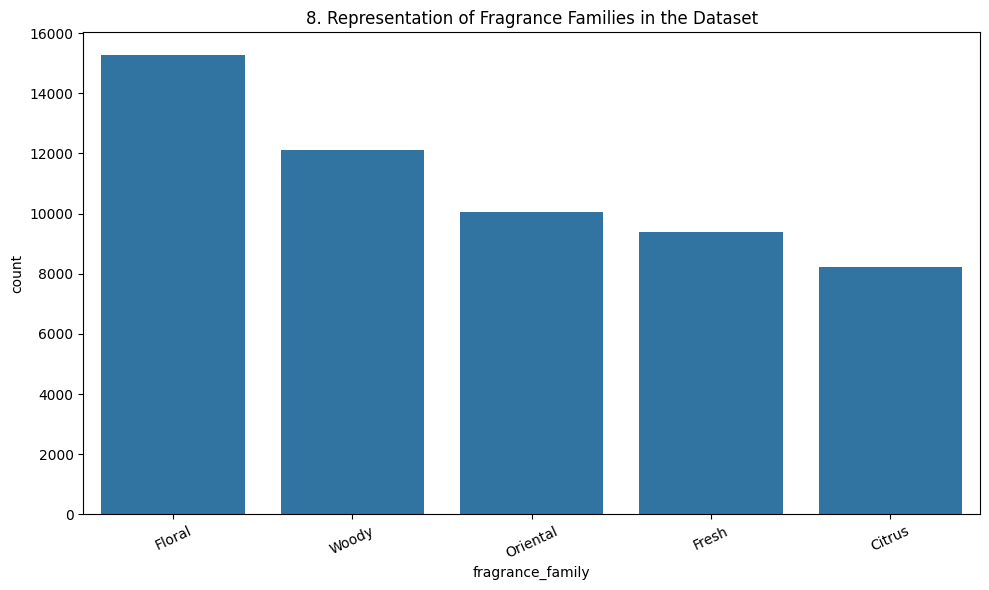

In [22]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='fragrance_family', order=df['fragrance_family'].value_counts().index)
plt.title(f'{plot_no}. Representation of Fragrance Families in the Dataset')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

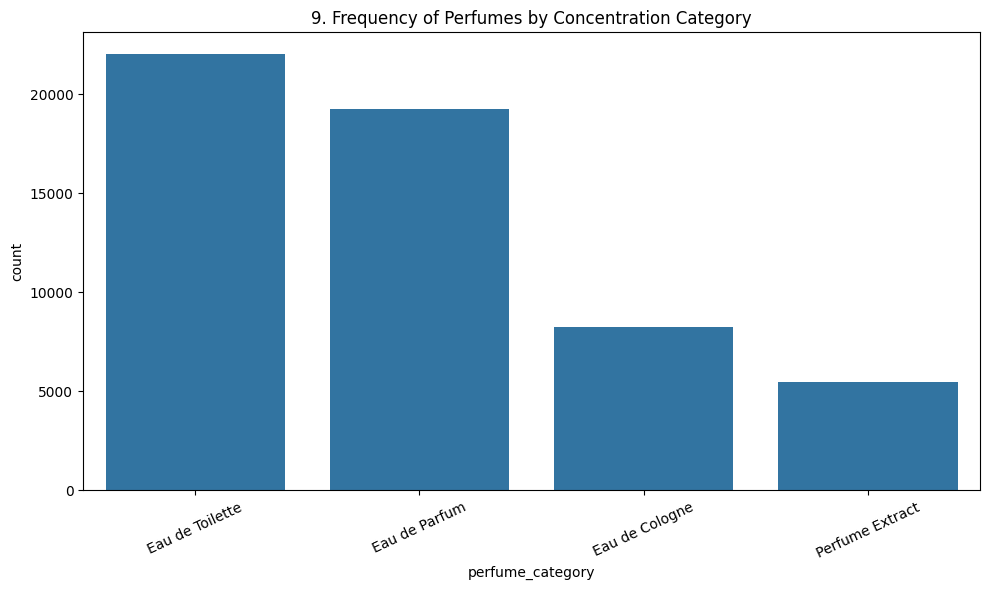

In [23]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='perfume_category', order=df['perfume_category'].value_counts().index)
plt.title(f'{plot_no}. Frequency of Perfumes by Concentration Category')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

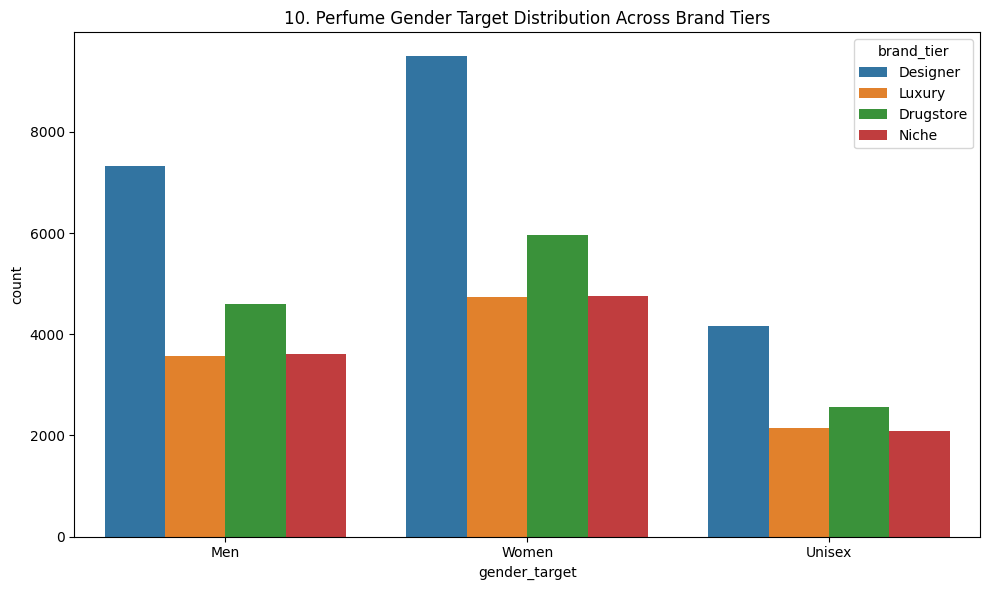

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='gender_target', hue='brand_tier')
plt.title(f'{plot_no}. Perfume Gender Target Distribution Across Brand Tiers')
show_fig()
plot_no += 1

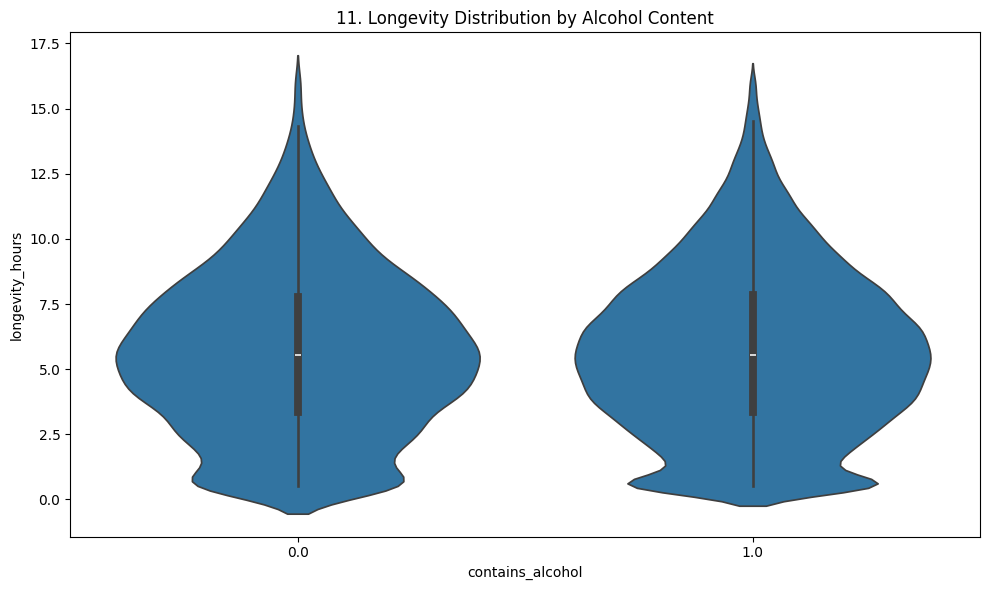

In [25]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='contains_alcohol', y='longevity_hours')
plt.title(f'{plot_no}. Longevity Distribution by Alcohol Content')
show_fig()
plot_no += 1

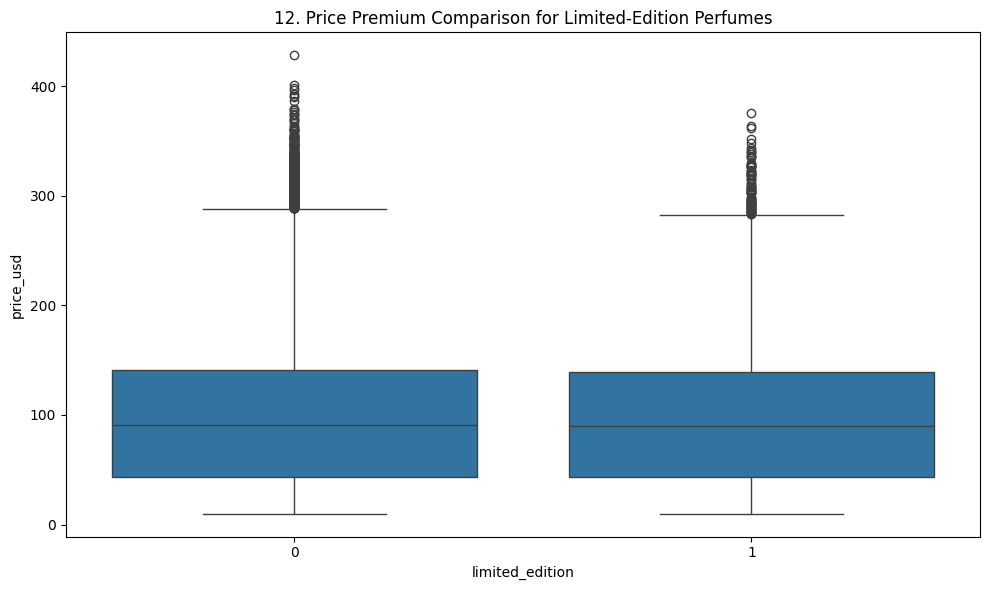

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='limited_edition', y='price_usd')
plt.title(f'{plot_no}. Price Premium Comparison for Limited-Edition Perfumes')
show_fig()
plot_no += 1

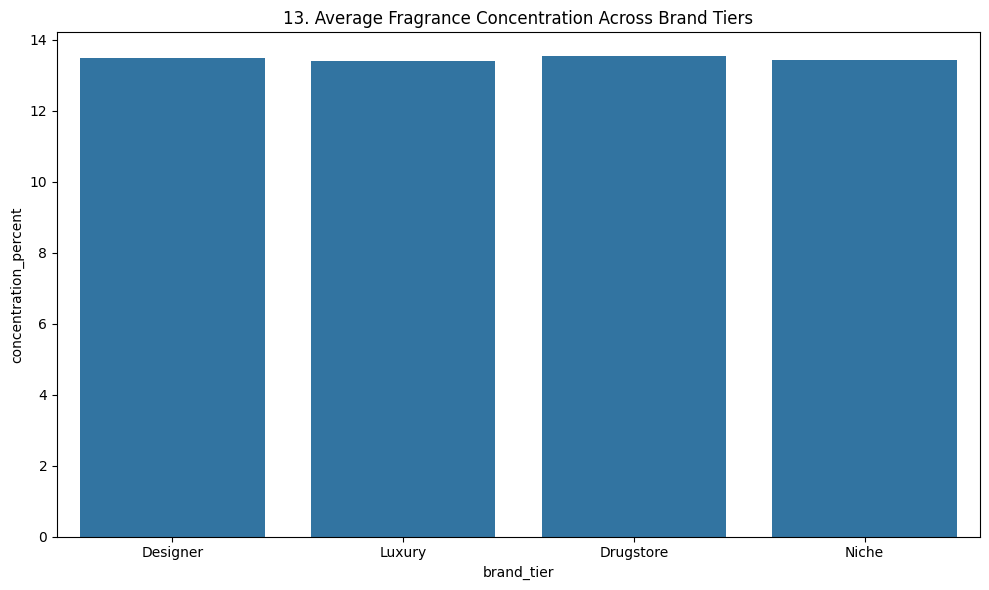

In [27]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='brand_tier', y='concentration_percent', errorbar=None)
plt.title(f'{plot_no}. Average Fragrance Concentration Across Brand Tiers')
show_fig()
plot_no += 1

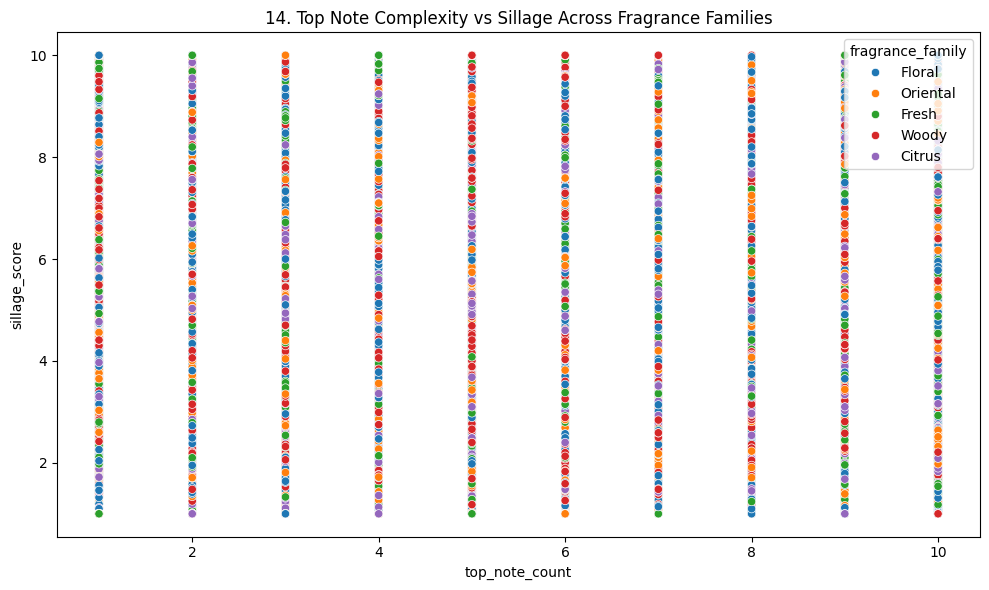

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='top_note_count', y='sillage_score', hue='fragrance_family')
plt.title(f'{plot_no}. Top Note Complexity vs Sillage Across Fragrance Families')
show_fig()
plot_no += 1

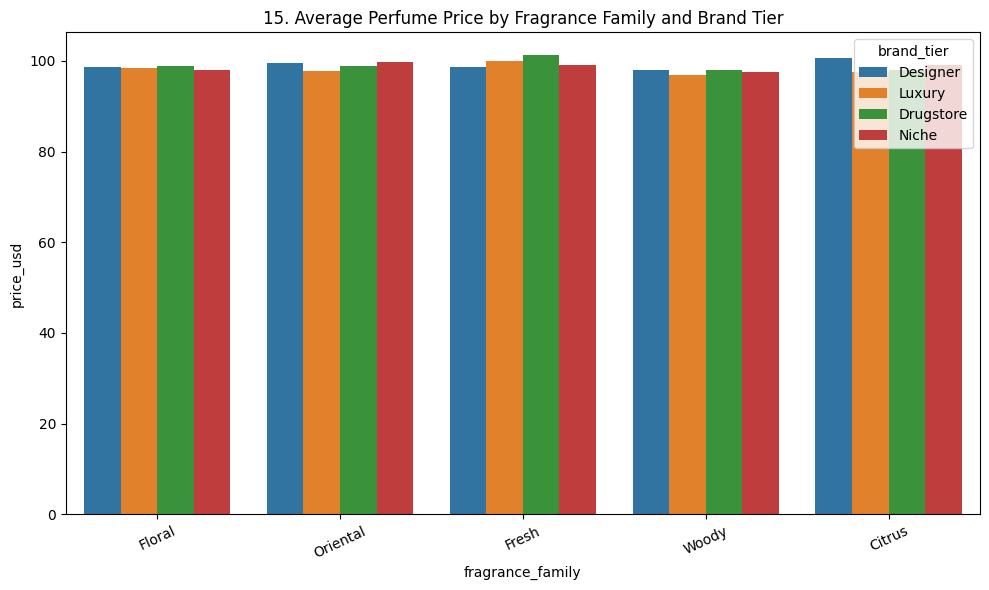

In [29]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='fragrance_family', y='price_usd', hue='brand_tier', errorbar=None)
plt.title(f'{plot_no}. Average Perfume Price by Fragrance Family and Brand Tier')
plt.xticks(rotation=25)
show_fig()
plot_no += 1

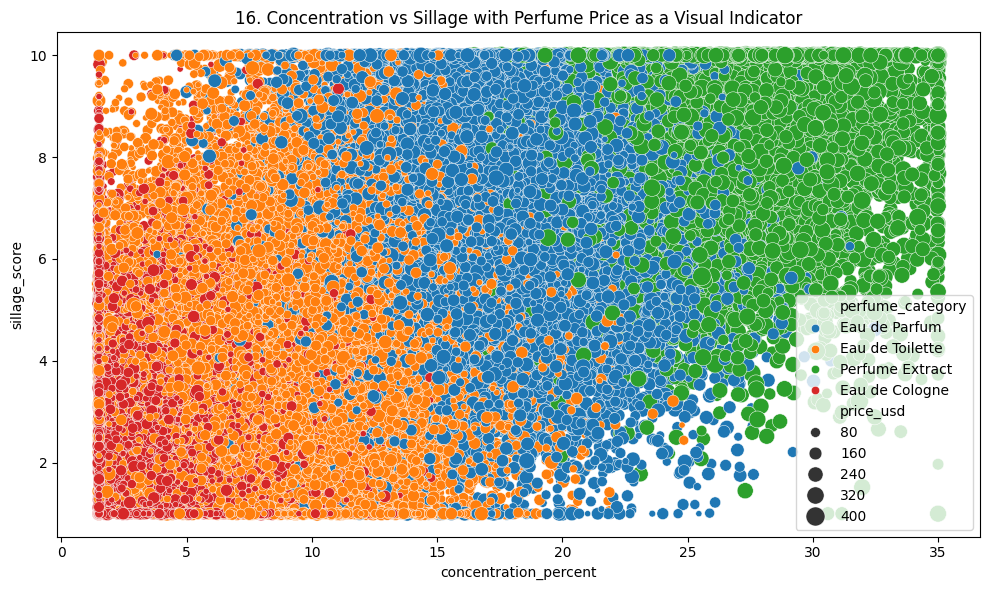

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='concentration_percent', y='sillage_score', size='price_usd', hue='perfume_category', sizes=(20,200))
plt.title(f'{plot_no}. Concentration vs Sillage with Perfume Price as a Visual Indicator')
show_fig()
plot_no += 1

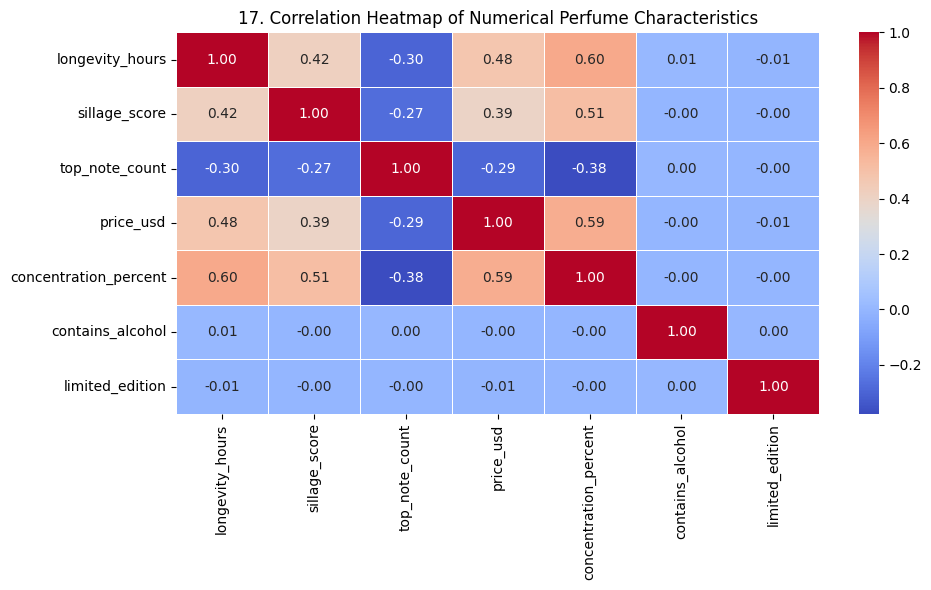

In [31]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Numerical Perfume Characteristics')
show_fig()
plot_no += 1

# Model Training

## Prepare features and target

In [32]:
data = df.dropna(subset=['longevity_hours']).copy()
X = data.drop(columns=['longevity_hours'])
y = data['longevity_hours'].astype('float32')

## Split training and testing data

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Build preprocessing pipelines

In [35]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Transform features without leaking test information

In [36]:
X_train = preprocessor.fit_transform(X_train).astype('float32')
X_test = preprocessor.transform(X_test).astype('float32')

## Standardize the target

In [37]:
y_mean = float(y_train.mean())
y_std = float(y_train.std())
y_train_scaled = ((y_train.to_numpy() - y_mean) / y_std).astype('float32')

## Set reproducible random seeds

In [38]:
tf.keras.utils.set_random_seed(42)

## Build a compact regularized ANN

In [39]:
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.15),
    Dense(32, activation='relu'),
    Dropout(0.10),
    Dense(16, activation='relu'),
    Dense(1)
])

## Compile the model

In [40]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='mse',
    metrics=['mae']
)

## Configure early stopping and learning-rate reduction

In [41]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=12,
        min_delta=0.001,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=5,
        min_lr=0.00001
    )
]

## Train the ANN

In [42]:
history = model.fit(
    X_train,
    y_train_scaled,
    validation_split=0.2,
    epochs=100,
    batch_size=128,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 0.7418 - mae: 0.6883 - val_loss: 0.5906 - val_mae: 0.6207 - learning_rate: 5.0000e-04
Epoch 2/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6018 - mae: 0.6245 - val_loss: 0.5413 - val_mae: 0.5919 - learning_rate: 5.0000e-04
Epoch 3/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.5721 - mae: 0.6091 - val_loss: 0.5304 - val_mae: 0.5862 - learning_rate: 5.0000e-04
Epoch 4/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.5596 - mae: 0.6027 - val_loss: 0.5232 - val_mae: 0.5830 - learning_rate: 5.0000e-04
Epoch 5/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5486 - mae: 0.5969 - val_loss: 0.5199 - val_mae: 0.5811 - learning_rate: 5.0000e-04
Epoch 6/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5426 - mae: 0.5940 - val_loss: 0.5183 - val_mae: 0.5804 - learning_rate: 5.0000e-04
Epoch 7/100
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5377 - mae: 0.5909 - val_loss: 0.5154 - val_mae: 0.5788

## Predict test-set longevity

In [43]:
y_pred = model.predict(X_test, verbose=0).ravel() * y_std + y_mean

## Evaluate ANN performance

In [44]:
ann_r2 = r2_score(y_test, y_pred)
ann_mae = mean_absolute_error(y_test, y_pred)
ann_rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"ANN R² Score: {ann_r2:.4f}")
print(f"ANN MAE: {ann_mae:.4f} hours")
print(f"ANN RMSE: {ann_rmse:.4f} hours")

ANN R² Score: 0.4746
ANN MAE: 1.8577 hours
ANN RMSE: 2.2964 hours


## Train a benchmark model on the same split

In [45]:
benchmark = ExtraTreesRegressor(
    n_estimators=150,
    min_samples_leaf=3,
    max_features=0.9,
    random_state=42,
    n_jobs=-1
)
benchmark.fit(X_train, y_train)
benchmark_pred = benchmark.predict(X_test)

## Compare ANN and Extra Trees fairly

In [46]:
print(f"\nExtra Trees R²: {r2_score(y_test, benchmark_pred):.4f}")
print(f"Extra Trees MAE: {mean_absolute_error(y_test, benchmark_pred):.4f}")
print(f"Extra Trees RMSE: {np.sqrt(mean_squared_error(y_test, benchmark_pred)):.4f}")


Extra Trees R²: 0.4477
Extra Trees MAE: 1.9036
Extra Trees RMSE: 2.3547


## Plot actual versus predicted values

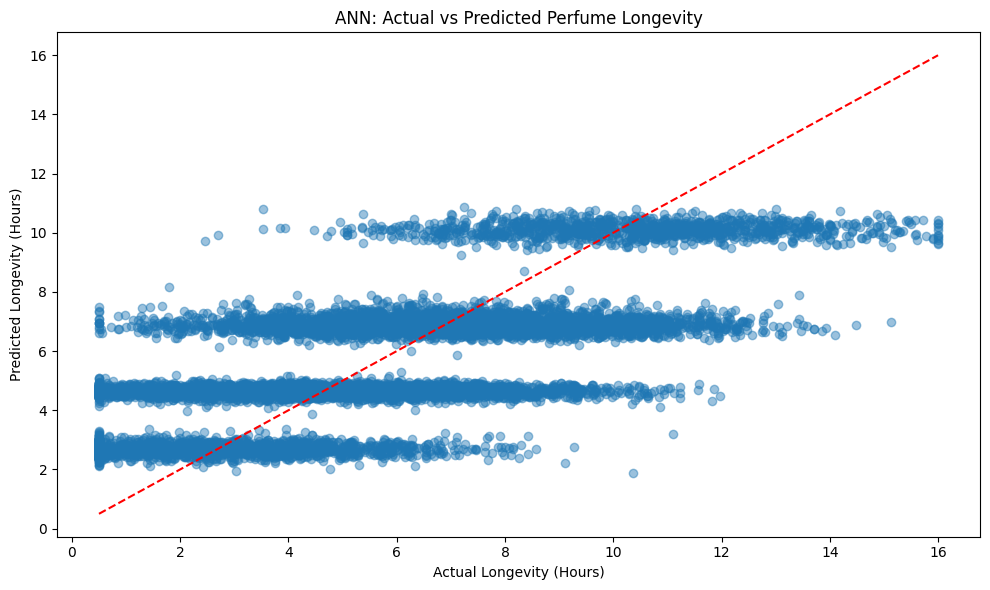

In [47]:
fig = plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.45)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel('Actual Longevity (Hours)')
plt.ylabel('Predicted Longevity (Hours)')
plt.title('ANN: Actual vs Predicted Perfume Longevity')
plt.tight_layout()
plt.show()

## Plot training and validation loss

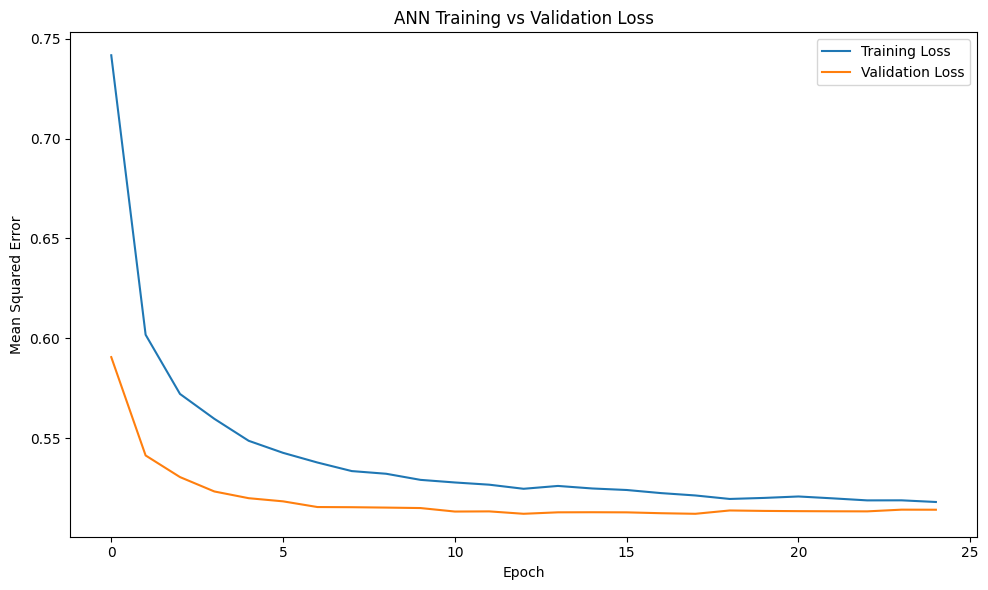

In [48]:
fig = plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.title('ANN Training vs Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [49]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │           1,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 64)                  │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 12,805 (50.02 KB)

 Trainable params: 4,225 (16.50 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 8,452 (33.02 KB)